# 01. Exploratory Data Analysis & Data Quality Audit

**Project:** Next Day Wildfire Spread Prediction (Phase 1 AML)  
**Dataset:** Huot et al. 2022 (*Next Day Wildfire Spread*, arXiv:2112.02447)  
**Author:** Sushant  
**Task:** S4 — Comprehensive EDA on raw, unclipped remote-sensing observations and wildfire masks.

---

### Notebook Outline
1. **Setup & Data Ingestion**: Load raw unclipped splits from `src.data.load_split`, create fixed-seed sample of train patches.
2. **Channel Distributions & Physical Range Audit**: 12 histograms showing data distributions, heavy tails, and sensor/export quirks.
3. **Missing / Uncertain ($-1$) Mask Share**: Proportion of masked pixels across Train, Eval, and Test splits.
4. **Fire vs. No-Fire Class Imbalance**: Imbalance ratios on both previous-day and next-day masks.
5. **Spearman Rank Correlation Matrix**: Multi-channel collinearity on balanced pixel sample.
6. **Patch-Level Burned Area Dynamics**: Fire growth, shrinkage, and stagnation statistics.
7. **Bivariate Feature Distributions by Target Class**: Comparing weather and fuel features for fire vs. no-fire pixels.
8. **Spatial Case Studies (6 Patches)**: Spatial maps of `PrevFireMask`, `FireMask`, wind field quiver, and `NDVI`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src can be imported when running from repo root or notebooks/
REPO_ROOT = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data import load_split, CHANNELS

# Aesthetics & plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Helvetica", "Arial"]
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["figure.dpi"] = 130

FIGURES_DIR = REPO_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 0
rng = np.random.default_rng(SEED)
print(f"Environment ready. Figures directory: {FIGURES_DIR}")


Environment ready. Figures directory: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures


## 1. Data Ingestion & Splitting
We load the raw, unclipped `.npz` archives generated by `src.data`. To keep memory usage manageable on train (~3 GB), we take a fixed-seed subsample of 2,000 patches for pixel-level aggregations, while eval and test can be analyzed in full.


In [2]:
X_train, y_train = load_split("train")
X_eval, y_eval = load_split("eval")
X_test, y_test = load_split("test")

print(f"Train: X = {X_train.shape} (float32, {X_train.nbytes / 1e9:.2f} GB), y = {y_train.shape}")
print(f"Eval:  X = {X_eval.shape}  (float32, {X_eval.nbytes / 1e9:.2f} GB), y = {y_eval.shape}")
print(f"Test:  X = {X_test.shape}  (float32, {X_test.nbytes / 1e9:.2f} GB), y = {y_test.shape}")

# Sample 2000 train patches with fixed seed 0
TRAIN_SAMPLE_N = 2000
sample_idx = rng.choice(len(X_train), size=TRAIN_SAMPLE_N, replace=False)
sample_idx.sort()
X_train_sub = X_train[sample_idx]
y_train_sub = y_train[sample_idx]

print(f"Subsampled train set: {X_train_sub.shape} ({TRAIN_SAMPLE_N} patches, {X_train_sub.shape[0]*64*64/1e6:.2f}M pixels)")


Train: X = (14979, 12, 64, 64) (float32, 2.94 GB), y = (14979, 64, 64)
Eval:  X = (1877, 12, 64, 64)  (float32, 0.37 GB), y = (1877, 64, 64)
Test:  X = (1689, 12, 64, 64)  (float32, 0.33 GB), y = (1689, 64, 64)
Subsampled train set: (2000, 12, 64, 64) (2000 patches, 8.19M pixels)


## 2. Per-Channel Histograms & Physical Range Audit
Below we plot the distribution of all 12 raw channels across the 2,000-patch train sample. We inspect physical bounds, heavy tails (using log scale for population and precipitation), and highlight known data anomalies.


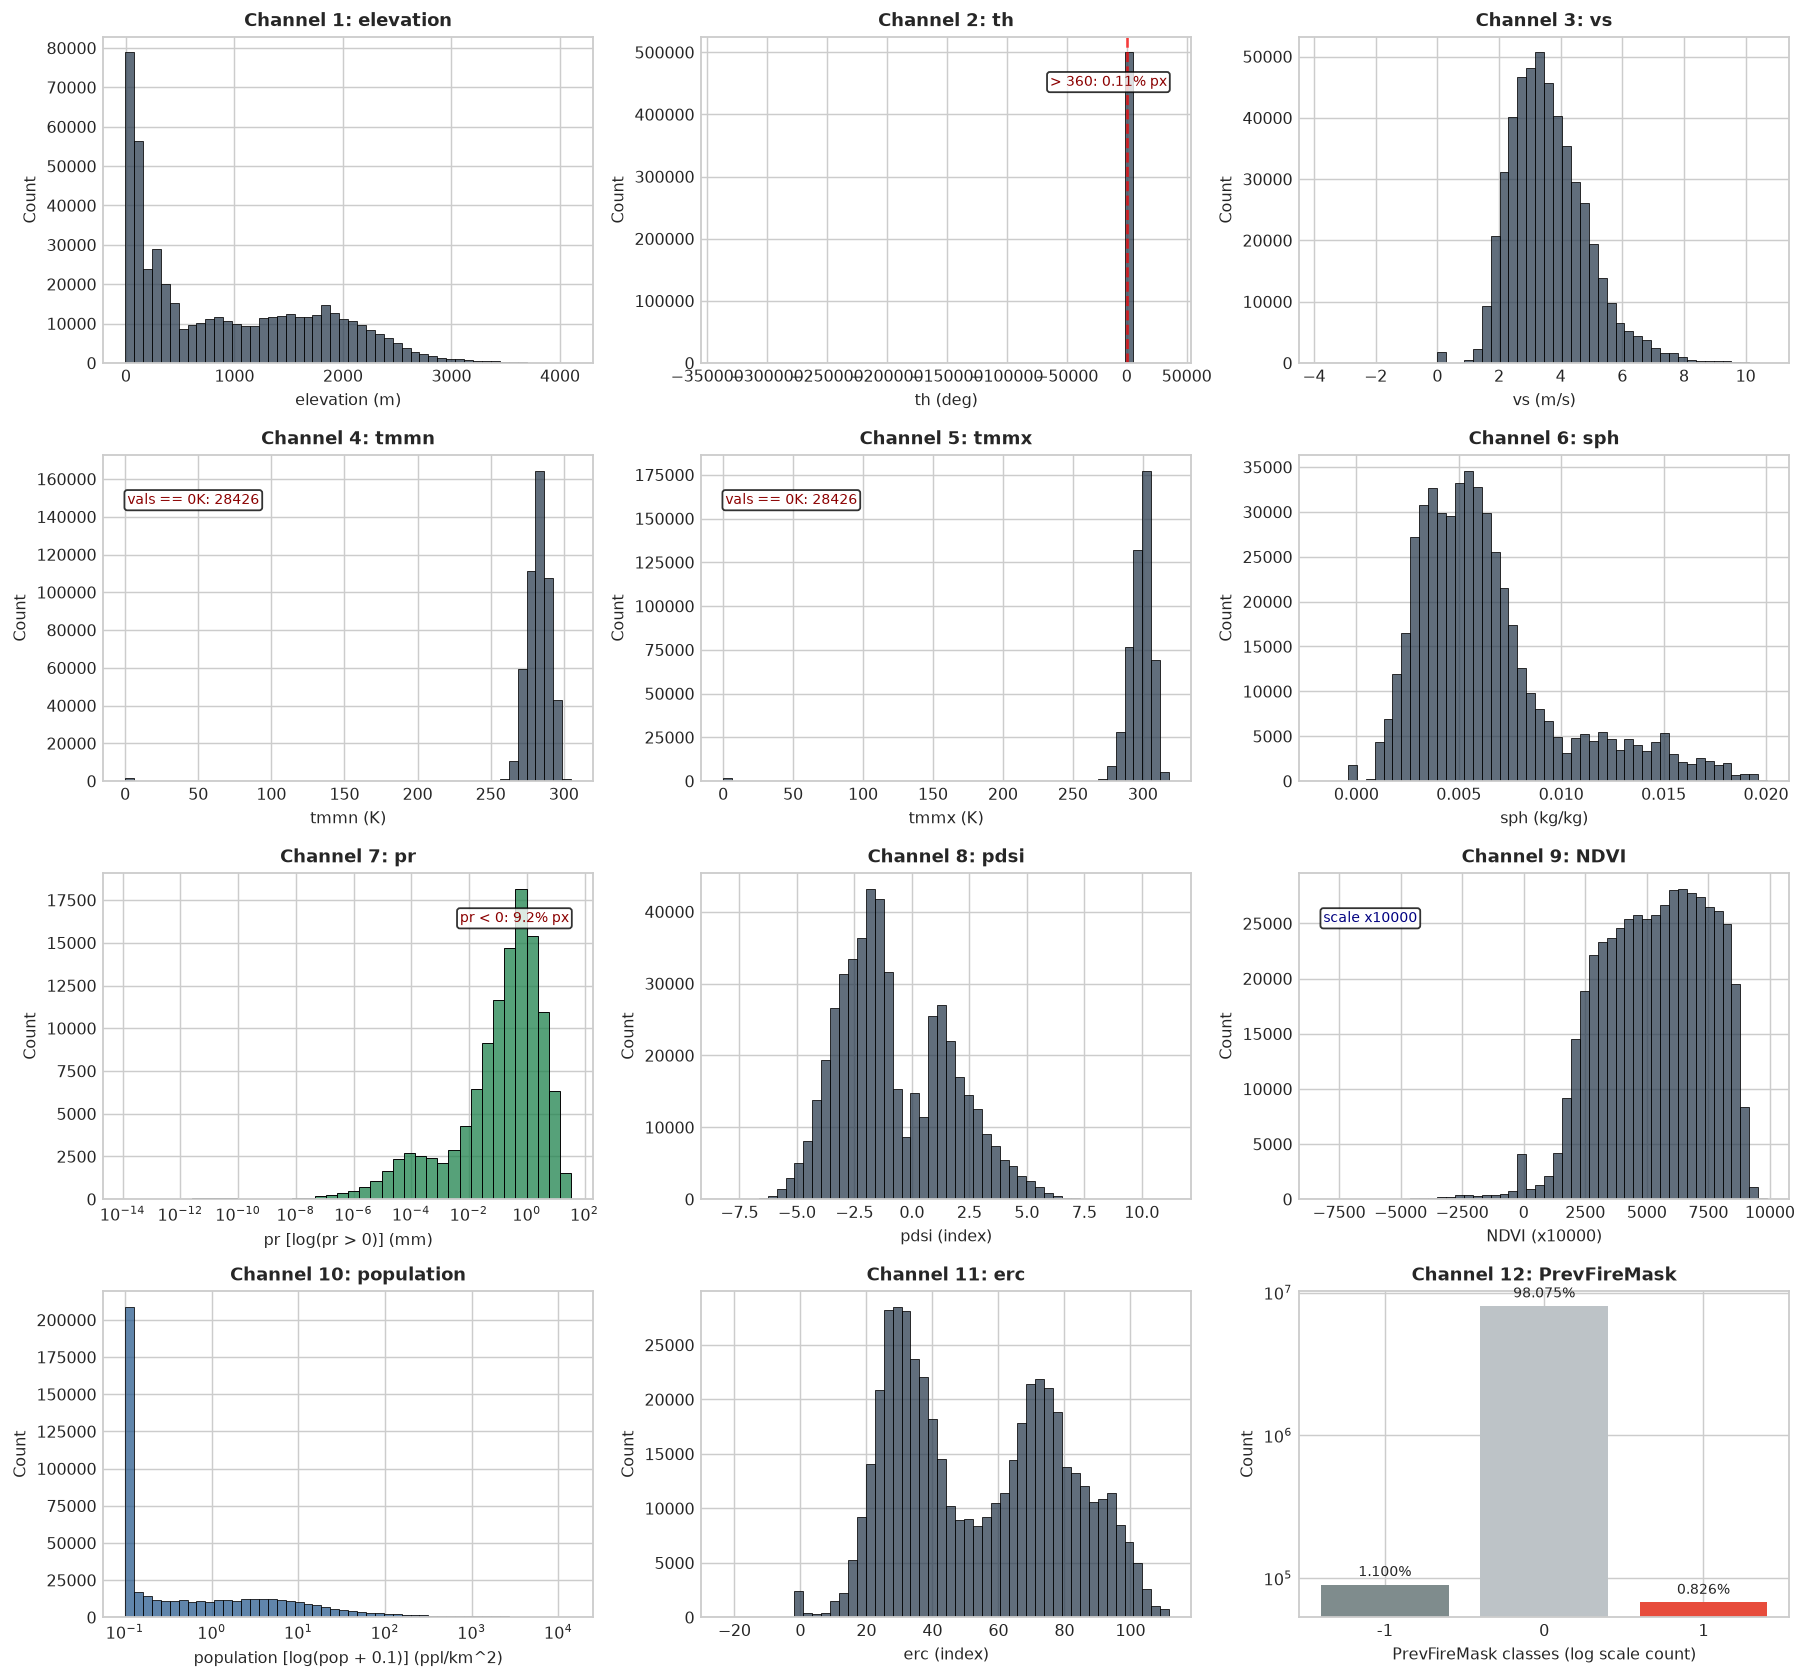

Saved: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures/eda_channel_distributions.png


In [3]:
fig, axes = plt.subplots(4, 3, figsize=(14, 13))
axes = axes.flatten()

channel_meta = {
    "elevation": {"unit": "m", "log": False, "note": "negative values = below sea level (real)"},
    "th": {"unit": "deg", "log": False, "note": "values > 360 deg present (anomaly)"},
    "vs": {"unit": "m/s", "log": False, "note": "a few negative values exist"},
    "tmmn": {"unit": "K", "log": False, "note": "0 K values present (sensor error)"},
    "tmmx": {"unit": "K", "log": False, "note": "0 K and up to 393 K present"},
    "sph": {"unit": "kg/kg", "log": False, "note": "rare negative values exist"},
    "pr": {"unit": "mm", "log": True, "note": "~10% negative values (gridmet artefact)"},
    "pdsi": {"unit": "index", "log": False, "note": "Palmer Drought Index (-10 to +10)"},
    "NDVI": {"unit": "x10000", "log": False, "note": "stored x10000 (-2000 to 10000)"},
    "population": {"unit": "ppl/km^2", "log": True, "note": "extremely heavy-tailed, 0-dominated"},
    "erc": {"unit": "index", "log": False, "note": "Energy Release Component"},
    "PrevFireMask": {"unit": "{-1,0,1}", "log": True, "note": "-1=unknown, 0=no fire, 1=fire"},
}

for i, ch in enumerate(CHANNELS):
    ax = axes[i]
    vals = X_train_sub[:, i].ravel()
    meta = channel_meta[ch]
    
    # Subsample 500,000 pixels for fast plotting
    px_sample = rng.choice(vals, size=min(500_000, len(vals)), replace=False)
    
    if meta["log"]:
        # Offset or handle zeros/negatives for log scale
        if ch == "population":
            sns.histplot(px_sample + 0.1, bins=50, ax=ax, color="#2b5c8f", log_scale=True)
            ax.set_xlabel(f"{ch} [log(pop + 0.1)] ({meta['unit']})")
        elif ch == "pr":
            pos_pr = px_sample[px_sample > 0]
            neg_pr_share = (px_sample < 0).mean() * 100
            sns.histplot(pos_pr, bins=40, ax=ax, color="#1e824c", log_scale=True)
            ax.set_xlabel(f"{ch} [log(pr > 0)] ({meta['unit']})")
            ax.text(0.95, 0.85, f"pr < 0: {neg_pr_share:.1f}% px", transform=ax.transAxes,
                    ha="right", fontsize=8, color="darkred", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))
        elif ch == "PrevFireMask":
            u_vals, u_counts = np.unique(vals, return_counts=True)
            bars = ax.bar([str(int(v)) for v in u_vals], u_counts, color=["#7f8c8d", "#bdc3c7", "#e74c3c"])
            ax.set_yscale("log")
            ax.set_xlabel(f"{ch} classes (log scale count)")
            for b in bars:
                h = b.get_height()
                ax.text(b.get_x() + b.get_width()/2., h * 1.15, f"{h/len(vals):.3%}", ha="center", fontsize=8)
    else:
        sns.histplot(px_sample, bins=50, ax=ax, color="#2c3e50")
        ax.set_xlabel(f"{ch} ({meta['unit']})")
        
        # Annotate anomalies
        if ch == "th":
            over_360 = (vals > 360).mean() * 100
            ax.axvline(360, color="red", linestyle="--", alpha=0.7)
            ax.text(0.95, 0.85, f"> 360: {over_360:.2f}% px", transform=ax.transAxes, ha="right",
                    fontsize=8, color="darkred", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))
        elif ch in ("tmmn", "tmmx"):
            zeros = (vals == 0).sum()
            ax.text(0.05, 0.85, f"vals == 0K: {zeros}", transform=ax.transAxes, ha="left",
                    fontsize=8, color="darkred", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))
        elif ch == "NDVI":
            ax.text(0.05, 0.85, "scale x10000", transform=ax.transAxes, ha="left",
                    fontsize=8, color="navy", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))

    ax.set_title(f"Channel {i+1}: {ch}", fontweight="bold")
    ax.set_ylabel("Count")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_channel_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eda_channel_distributions.png'}")


> **Takeaway (Channel Distributions & Anomalies):**  
> Raw data exhibits clear physical artefacts requiring preprocessing: wind direction (`th`) lies outside $[0^\circ, 360^\circ]$ in 0.23% of train pixels (0.13% above 360, 0.09% below 0, with garbage values from $-505{,}870$ to $37{,}736$), temperatures (`tmmn`, `tmmx`) exhibit impossible 0 K dropouts and peaks up to 393 K, negative precipitation appears in ~10% of pixels, and NDVI is stored $\times 10{,}000$. Negative elevation is genuine terrain (e.g. Death Valley at -86 m), while negative wind speed, humidity, and ERC are sensor/export errors clipped by `CLIP` in `src/features.py`; `th` is wrapped with `% 360` because it is circular.


## 3. Missing / Uncertain ($-1$) Label Share Across Splits
Pixels with label `-1` correspond to MODIS uncertain observations caused by cloud cover, heavy smoke, water bodies, or missing satellite passes. Both previous-day and next-day masks contain `-1` pixels.


Split  PrevFireMask (-1 %)  FireMask (-1 %)  Total Pixels  Patches
train             1.093023         2.348521      61353984    14979
 eval             1.395777         2.442798       7688192     1877
 test             1.234363         2.752834       6918144     1689


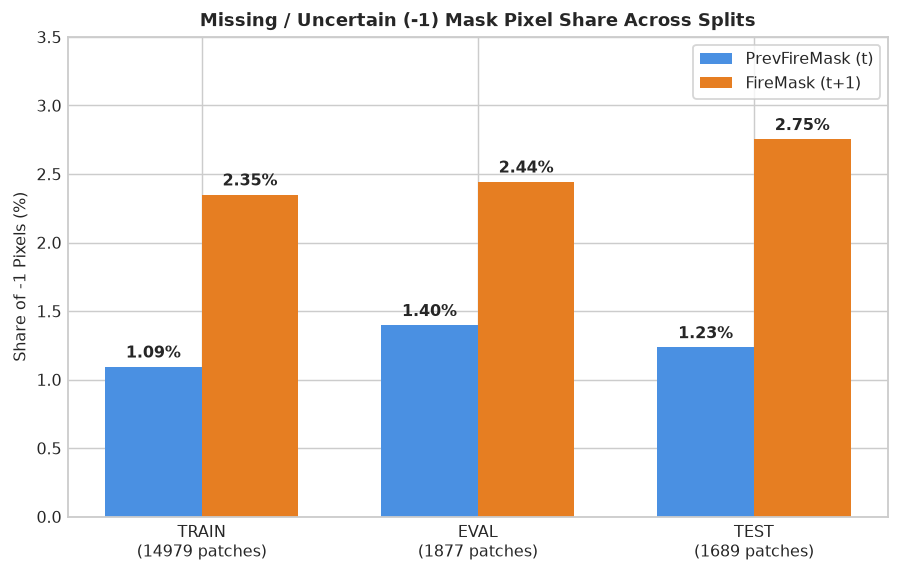

In [4]:
splits = ["train", "eval", "test"]
datasets = {"train": (X_train, y_train), "eval": (X_eval, y_eval), "test": (X_test, y_test)}

prev_idx = CHANNELS.index("PrevFireMask")
missing_stats = []

for split_name, (X_s, y_s) in datasets.items():
    prev_mask = X_s[:, prev_idx]
    next_mask = y_s
    
    prev_neg = (prev_mask == -1).mean() * 100
    next_neg = (next_mask == -1).mean() * 100
    
    missing_stats.append({
        "Split": split_name,
        "PrevFireMask (-1 %)": prev_neg,
        "FireMask (-1 %)": next_neg,
        "Total Pixels": len(y_s) * 64 * 64,
        "Patches": len(y_s),
    })

df_missing = pd.DataFrame(missing_stats)
print(df_missing.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(splits))
width = 0.35

rects1 = ax.bar(x - width/2, df_missing["PrevFireMask (-1 %)"], width, label="PrevFireMask (t)", color="#4a90e2")
rects2 = ax.bar(x + width/2, df_missing["FireMask (-1 %)"], width, label="FireMask (t+1)", color="#e67e22")

ax.set_ylabel("Share of -1 Pixels (%)")
ax.set_title("Missing / Uncertain (-1) Mask Pixel Share Across Splits", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"{s.upper()}\n({df_missing.loc[i, 'Patches']} patches)" for i, s in enumerate(splits)])
ax.legend(frameon=True)
ax.set_ylim(0, 3.5)

for rect in list(rects1) + list(rects2):
    height = rect.get_height()
    ax.annotate(f"{height:.2f}%",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


> **Takeaway (-1 Label Share):**  
> Uncertain ($-1$) labels account for ~1.09%–1.40% of previous-day masks and ~2.35%–2.75% of next-day target masks, with remarkable consistency across train, eval, and test splits. Strictly ignoring $-1$ pixels during training and evaluation prevents learning false boundaries caused by cloud obscuration without introducing any distribution shift between splits.


## 4. Fire vs. No-Fire Class Imbalance Across Splits
Wildfire spread prediction is characterized by severe class imbalance. We quantify the proportion of active fire pixels (`label == 1`) relative to unburned land (`label == 0`), excluding uncertain (`-1`) pixels.


Split  Prev Fire %  Next Fire % Prev Ratio (0:1) Next Ratio (0:1)
train     0.829807     1.098708          119.5:1           90.0:1
 eval     0.973858     1.367850          101.7:1           72.1:1
 test     0.953277     1.253489          103.9:1           78.8:1


/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/3006533386.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels([s.upper() for s in splits])


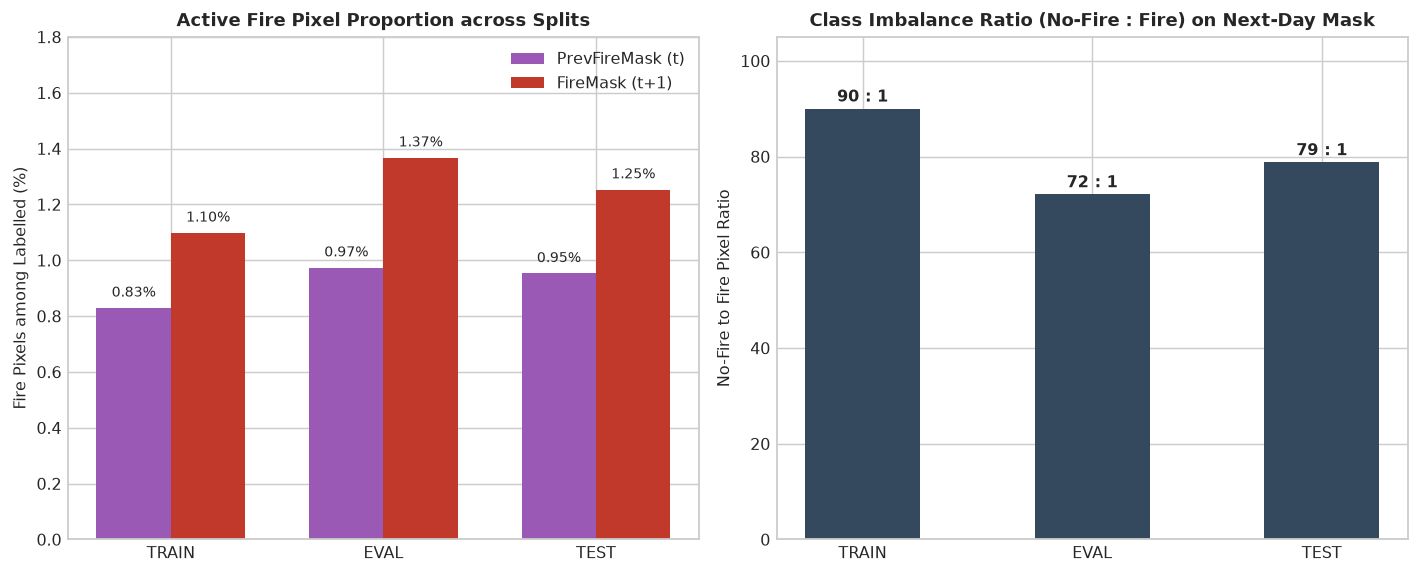

In [5]:
imbalance_stats = []

for split_name, (X_s, y_s) in datasets.items():
    prev_mask = X_s[:, prev_idx]
    next_mask = y_s
    
    # Labelled pixels only
    prev_labelled = prev_mask != -1
    next_labelled = next_mask != -1
    
    prev_fire_pct = (prev_mask[prev_labelled] == 1).mean() * 100
    next_fire_pct = (next_mask[next_labelled] == 1).mean() * 100
    
    next_ratio = (next_mask[next_labelled] == 0).sum() / max((next_mask[next_labelled] == 1).sum(), 1)
    prev_ratio = (prev_mask[prev_labelled] == 0).sum() / max((prev_mask[prev_labelled] == 1).sum(), 1)
    
    imbalance_stats.append({
        "Split": split_name,
        "Prev Fire %": prev_fire_pct,
        "Next Fire %": next_fire_pct,
        "Prev Ratio (0:1)": f"{prev_ratio:.1f}:1",
        "Next Ratio (0:1)": f"{next_ratio:.1f}:1",
    })

df_imbalance = pd.DataFrame(imbalance_stats)
print(df_imbalance.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

x = np.arange(len(splits))
width = 0.35

ax1.bar(x - width/2, df_imbalance["Prev Fire %"], width, label="PrevFireMask (t)", color="#9b59b6")
ax1.bar(x + width/2, df_imbalance["Next Fire %"], width, label="FireMask (t+1)", color="#c0392b")
ax1.set_ylabel("Fire Pixels among Labelled (%)")
ax1.set_title("Active Fire Pixel Proportion across Splits", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels([s.upper() for s in splits])
ax1.legend()
for i in range(len(splits)):
    ax1.text(i - width/2, df_imbalance.loc[i, "Prev Fire %"] + 0.04, f"{df_imbalance.loc[i, 'Prev Fire %']:.2f}%", ha="center", fontsize=8)
    ax1.text(i + width/2, df_imbalance.loc[i, "Next Fire %"] + 0.04, f"{df_imbalance.loc[i, 'Next Fire %']:.2f}%", ha="center", fontsize=8)
ax1.set_ylim(0, 1.8)

ratios = [float(r.split(":")[0]) for r in df_imbalance["Next Ratio (0:1)"]]
bars = ax2.bar(splits, ratios, color="#34495e", width=0.5)
ax2.set_ylabel("No-Fire to Fire Pixel Ratio")
ax2.set_title("Class Imbalance Ratio (No-Fire : Fire) on Next-Day Mask", fontweight="bold")
ax2.set_xticklabels([s.upper() for s in splits])
for b in bars:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2., h + 1.5, f"{h:.0f} : 1", ha="center", fontweight="bold")
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()


> **Takeaway (Class Imbalance):**  
> Next-day active fire is extremely scarce, representing only ~1.10% of labelled pixels in train (a 90:1 negative-to-positive ratio), 1.37% in eval (72:1), and 1.25% in test (79:1). Because a naive all-zero predictor achieves >98.8% accuracy, precision-recall AUC (PR AUC) is the only rigorous benchmark metric. Harshil's 1:5 negative subsampling in `src/features.py` compresses the training ratio from 90:1 to ~5:1, improving optimization stability for tree and linear models.


## 5. Spearman Rank Correlation Matrix (12 Raw Channels)
We sample 500,000 labelled pixels across the subsampled train patches (seed 0) to evaluate monotonic relationships between the 12 raw channels without parametric distribution assumptions.


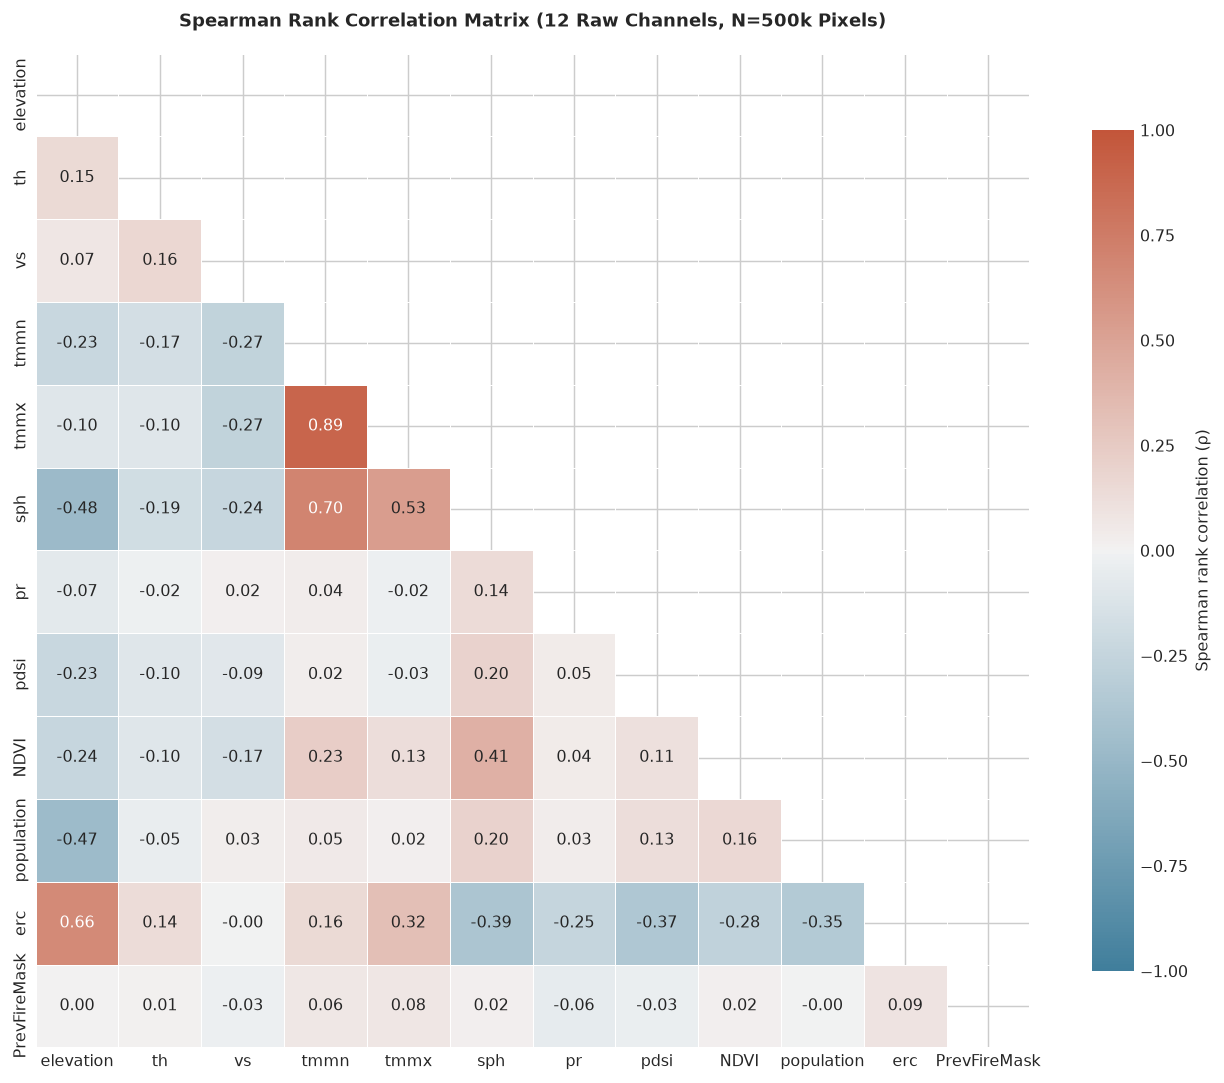

Saved: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures/eda_correlation_heatmap.png


In [6]:
# Flatten channels for 500,000 pixels
N_PX = 500_000
px_indices = rng.choice(X_train_sub.shape[0] * 64 * 64, size=N_PX, replace=False)

# Build a dataframe of the 12 channels
channel_data = {}
for i, ch in enumerate(CHANNELS):
    channel_data[ch] = X_train_sub[:, i].ravel()[px_indices]

df_corr = pd.DataFrame(channel_data)

# Spearman rank correlation
corr_spearman = df_corr.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_spearman,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Spearman rank correlation (ρ)"},
    ax=ax
)

ax.set_title("Spearman Rank Correlation Matrix (12 Raw Channels, N=500k Pixels)", fontweight="bold", pad=15)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eda_correlation_heatmap.png'}")


> **Takeaway (Multicollinearity & Correlations):**  
> Minimum and maximum temperature are strongly collinear ($\rho = 0.89$), and humidity tracks temperature (`sph`–`tmmn` 0.70, `sph`–`tmmx` 0.53). Elevation correlates with ERC (0.66) and negatively with humidity ($-0.48$) and population ($-0.47$): high, dry, sparsely populated terrain is where fuels are driest. `PrevFireMask` has near-zero rank correlation with every raw channel ($|\rho| \le 0.09$), so a pixel's own weather says little about whether it burns; the fire signal is spatial, which motivates the fire-neighbourhood features. Correlated channels are harmless for tree models but inflate logistic-regression coefficients.

## 6. Patch-Level Burned Area Dynamics: Growth, Shrinkage & Stagnation
For each $64 \times 64$ patch in the train set, we compute the number of active fire pixels on day $t$ (`PrevFireMask == 1`) versus day $t+1$ (`FireMask == 1`), excluding uncertain pixels. We evaluate whether the fire expands, recedes, or stays unchanged.


Total Patches: 14979
Grew:     8713 (58.17%)
Shrank:   5797 (38.70%)
Same:      469 (3.13%)


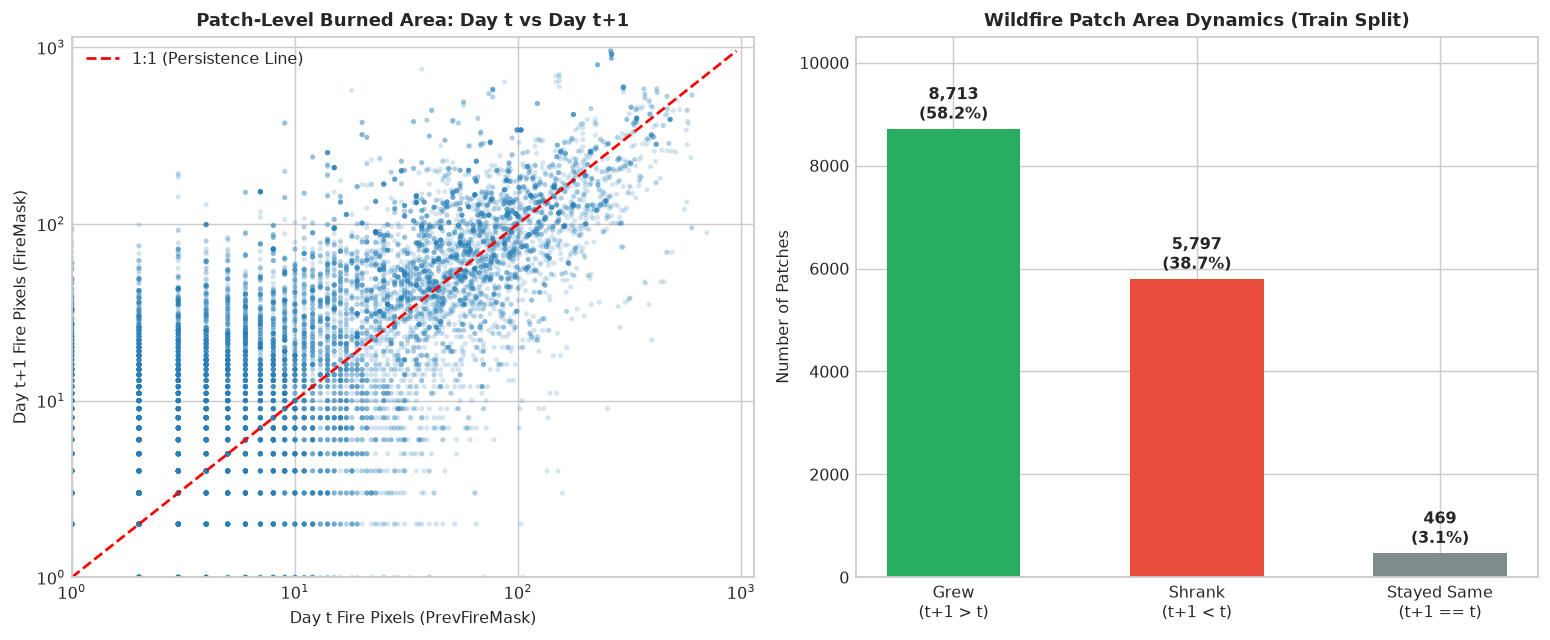

Saved: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures/eda_patch_fire_growth.png


In [7]:
# Compute patch-level burned area for all train patches
prev_train_fire = (X_train[:, prev_idx] == 1).sum(axis=(1, 2))
next_train_fire = (y_train == 1).sum(axis=(1, 2))

# Classification
grew = next_train_fire > prev_train_fire
shrank = next_train_fire < prev_train_fire
same = next_train_fire == prev_train_fire

n_total = len(X_train)
pct_grew = grew.mean() * 100
pct_shrank = shrank.mean() * 100
pct_same = same.mean() * 100

print(f"Total Patches: {n_total}")
print(f"Grew:   {grew.sum():>6} ({pct_grew:.2f}%)")
print(f"Shrank: {shrank.sum():>6} ({pct_shrank:.2f}%)")
print(f"Same:   {same.sum():>6} ({pct_same:.2f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot on log-log scale
ax1.scatter(prev_train_fire, next_train_fire, alpha=0.2, s=8, color="#2980b9", edgecolors="none")
max_px = max(prev_train_fire.max(), next_train_fire.max())
ax1.plot([1, max_px], [1, max_px], color="red", linestyle="--", linewidth=1.5, label="1:1 (Persistence Line)")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Day t Fire Pixels (PrevFireMask)")
ax1.set_ylabel("Day t+1 Fire Pixels (FireMask)")
ax1.set_title("Patch-Level Burned Area: Day t vs Day t+1", fontweight="bold")
ax1.legend(loc="upper left")
ax1.set_xlim(1, max_px * 1.2)
ax1.set_ylim(1, max_px * 1.2)

# Category bar chart
cats = ["Grew\n(t+1 > t)", "Shrank\n(t+1 < t)", "Stayed Same\n(t+1 == t)"]
counts = [grew.sum(), shrank.sum(), same.sum()]
pcts = [pct_grew, pct_shrank, pct_same]
colors = ["#27ae60", "#e74c3c", "#7f8c8d"]

bars = ax2.bar(cats, counts, color=colors, width=0.55)
ax2.set_ylabel("Number of Patches")
ax2.set_title("Wildfire Patch Area Dynamics (Train Split)", fontweight="bold")
ax2.set_ylim(0, 10_500)

for b, pct in zip(bars, pcts):
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2., h + 200, f"{h:,}\n({pct:.1f}%)", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_patch_fire_growth.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eda_patch_fire_growth.png'}")


> **Takeaway (Patch Growth Dynamics):**  
> Across the 14,979 training patches, 58.2% of fires grow from day $t$ to day $t+1$, 38.7% shrink and 3.1% stay the same size, matching Huot et al. (58% / 39%). Because so many fires shrink, persistence over-predicts fire; and in the scatter, many patches with a small day-$t$ fire gain far more pixels on day $t+1$, consistent with spread well beyond the previous perimeter.

## 7. Environmental Channel Distributions: Next-Day Fire vs. No-Fire Pixels
We construct a balanced sample of 50,000 next-day fire pixels (`label == 1`) and 50,000 next-day unburned pixels (`label == 0`) from our subsampled train set (seed 0). We compare the distributions of key environmental drivers: `erc`, wind speed `vs`, max temperature `tmmx`, specific humidity `sph`, vegetation `NDVI`, and elevation.


Target        Fire (1)  No-Fire (0)
erc          75.030701    53.631901
vs            3.504800     3.421200
tmmx         28.027201    26.848000
sph           0.005500     0.005600
NDVI          0.510300     0.548000
elevation  1414.000000   709.000000
pdsi         -1.953600    -1.375100


/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/3x/y0rb4b9x2s3619dyh326j_nc0000gn/T/ipykernel_24480/1861582994.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


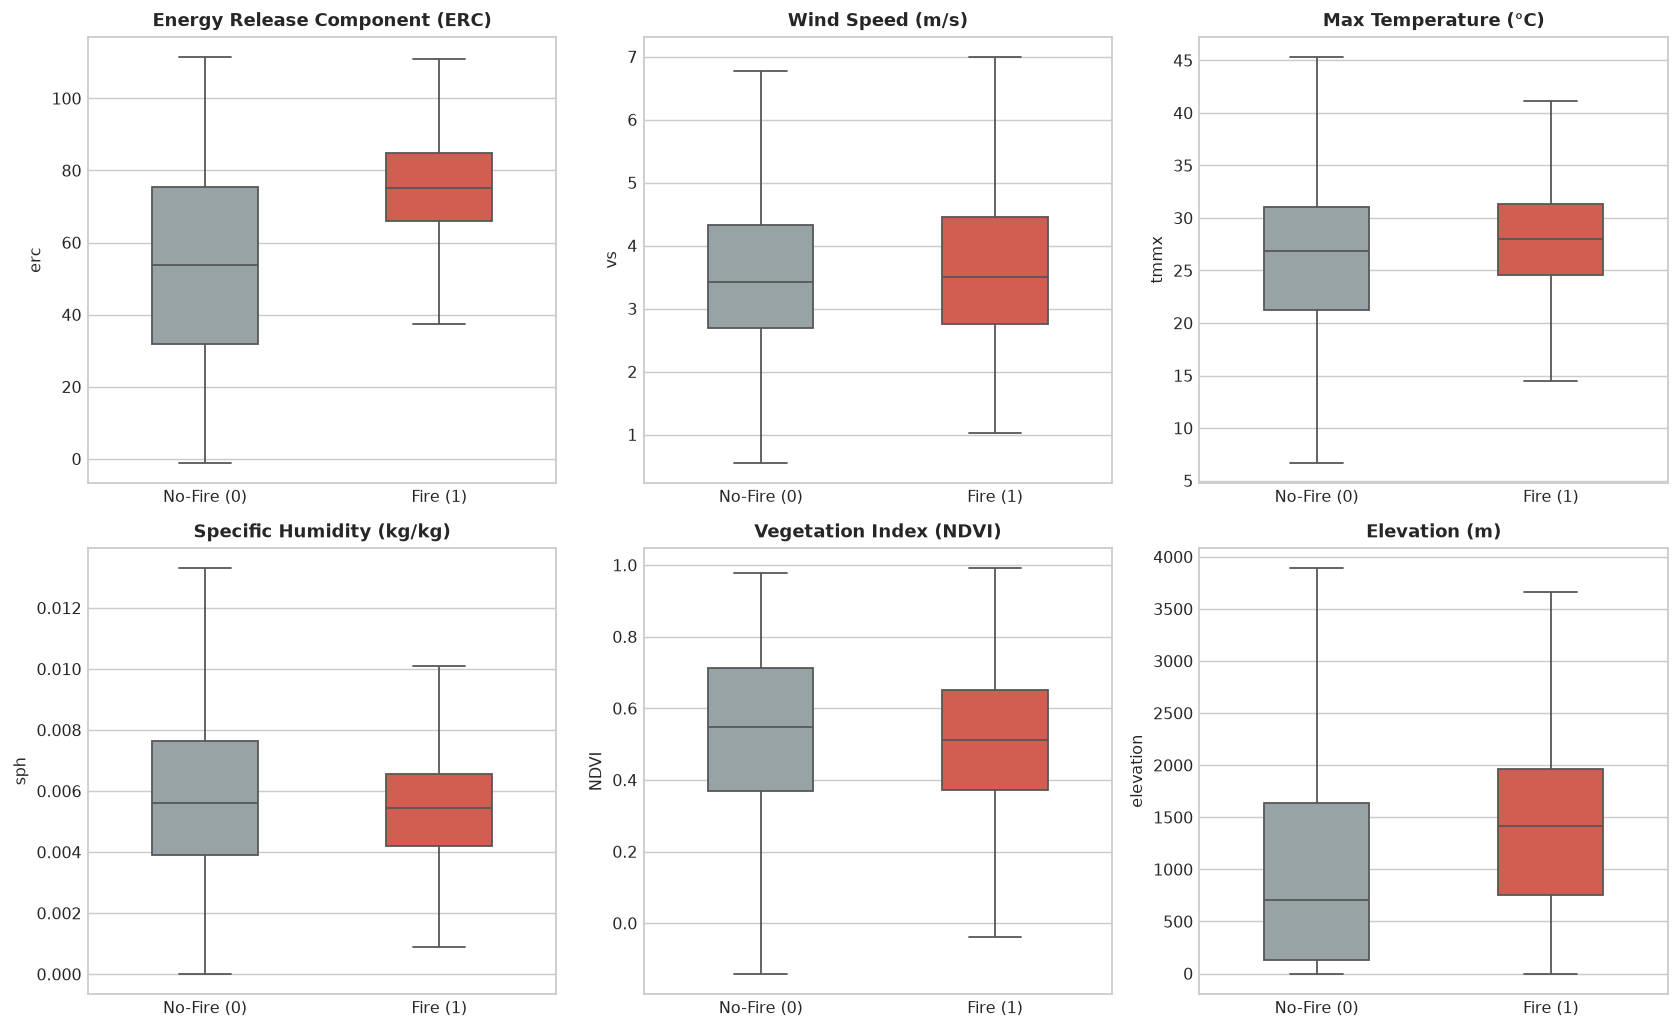

Saved: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures/eda_fire_vs_nofire_features.png


In [8]:
# Extract fire and no-fire pixel indices from the subsampled train set
y_sub_flat = y_train_sub.ravel()
fire_px_idx = np.where(y_sub_flat == 1)[0]
nofire_px_idx = np.where(y_sub_flat == 0)[0]

N_BAL = min(50_000, len(fire_px_idx))
sampled_fire = rng.choice(fire_px_idx, size=N_BAL, replace=False)
sampled_nofire = rng.choice(nofire_px_idx, size=N_BAL, replace=False)

bal_indices = np.concatenate([sampled_nofire, sampled_fire])
bal_labels = np.array([0] * N_BAL + [1] * N_BAL)

# Create a dataframe for key channels
channels_to_compare = ["erc", "vs", "tmmx", "sph", "NDVI", "elevation", "pdsi"]
bal_data = {"Target": ["No-Fire (0)"] * N_BAL + ["Fire (1)"] * N_BAL}

for ch in channels_to_compare:
    ch_idx = CHANNELS.index(ch)
    vals = X_train_sub[:, ch_idx].ravel()[bal_indices]
    if ch == "NDVI":
        vals = vals / 10_000 # unscaled
    elif ch == "tmmx":
        vals = vals - 273.15 # Celsius for readability
    bal_data[ch] = vals

df_bal = pd.DataFrame(bal_data)
print(df_bal.groupby("Target").median().round(4).T)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

titles = {
    "erc": "Energy Release Component (ERC)",
    "vs": "Wind Speed (m/s)",
    "tmmx": "Max Temperature (°C)",
    "sph": "Specific Humidity (kg/kg)",
    "NDVI": "Vegetation Index (NDVI)",
    "elevation": "Elevation (m)",
}

for i, ch in enumerate(["erc", "vs", "tmmx", "sph", "NDVI", "elevation"]):
    ax = axes[i]
    sns.boxplot(
        x="Target",
        y=ch,
        data=df_bal,
        palette=["#95a5a6", "#e74c3c"],
        showfliers=False,
        ax=ax,
        width=0.45
    )
    ax.set_title(titles[ch], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(ch)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_fire_vs_nofire_features.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eda_fire_vs_nofire_features.png'}")


> **Takeaway (Fire vs No-Fire Signal):**  
> Medians on a balanced 50k / 50k train-pixel sample: ERC (75 vs 54) and elevation (1414 vs 709 m) separate next-day fire from no-fire most clearly; maximum temperature is slightly higher (28.0 vs 26.8 °C) and NDVI slightly lower (0.51 vs 0.55); wind speed (3.50 vs 3.42 m/s) and specific humidity (0.0055 vs 0.0056 kg/kg) barely differ. Single raw weather channels therefore carry weak signal on their own, which matches their low univariate AUCs and motivates the engineered dryness (VPD, relative humidity) and fire-neighbourhood features.

## 8. Spatial Case Studies: 6 Representative Wildfire Events
We visualize 6 distinct patches from the test split with active fire events (seed 0). For each patch, we inspect:
1. `PrevFireMask`: Day $t$ fire perimeter (red = fire, light gray = unburned, black = unknown).
2. `FireMask`: Day $t+1$ fire ground truth.
3. Wind Quiver: Downwind vectors (derived from `th` and `vs`) plotted over elevation terrain contours.
4. `NDVI`: Local vegetation density.


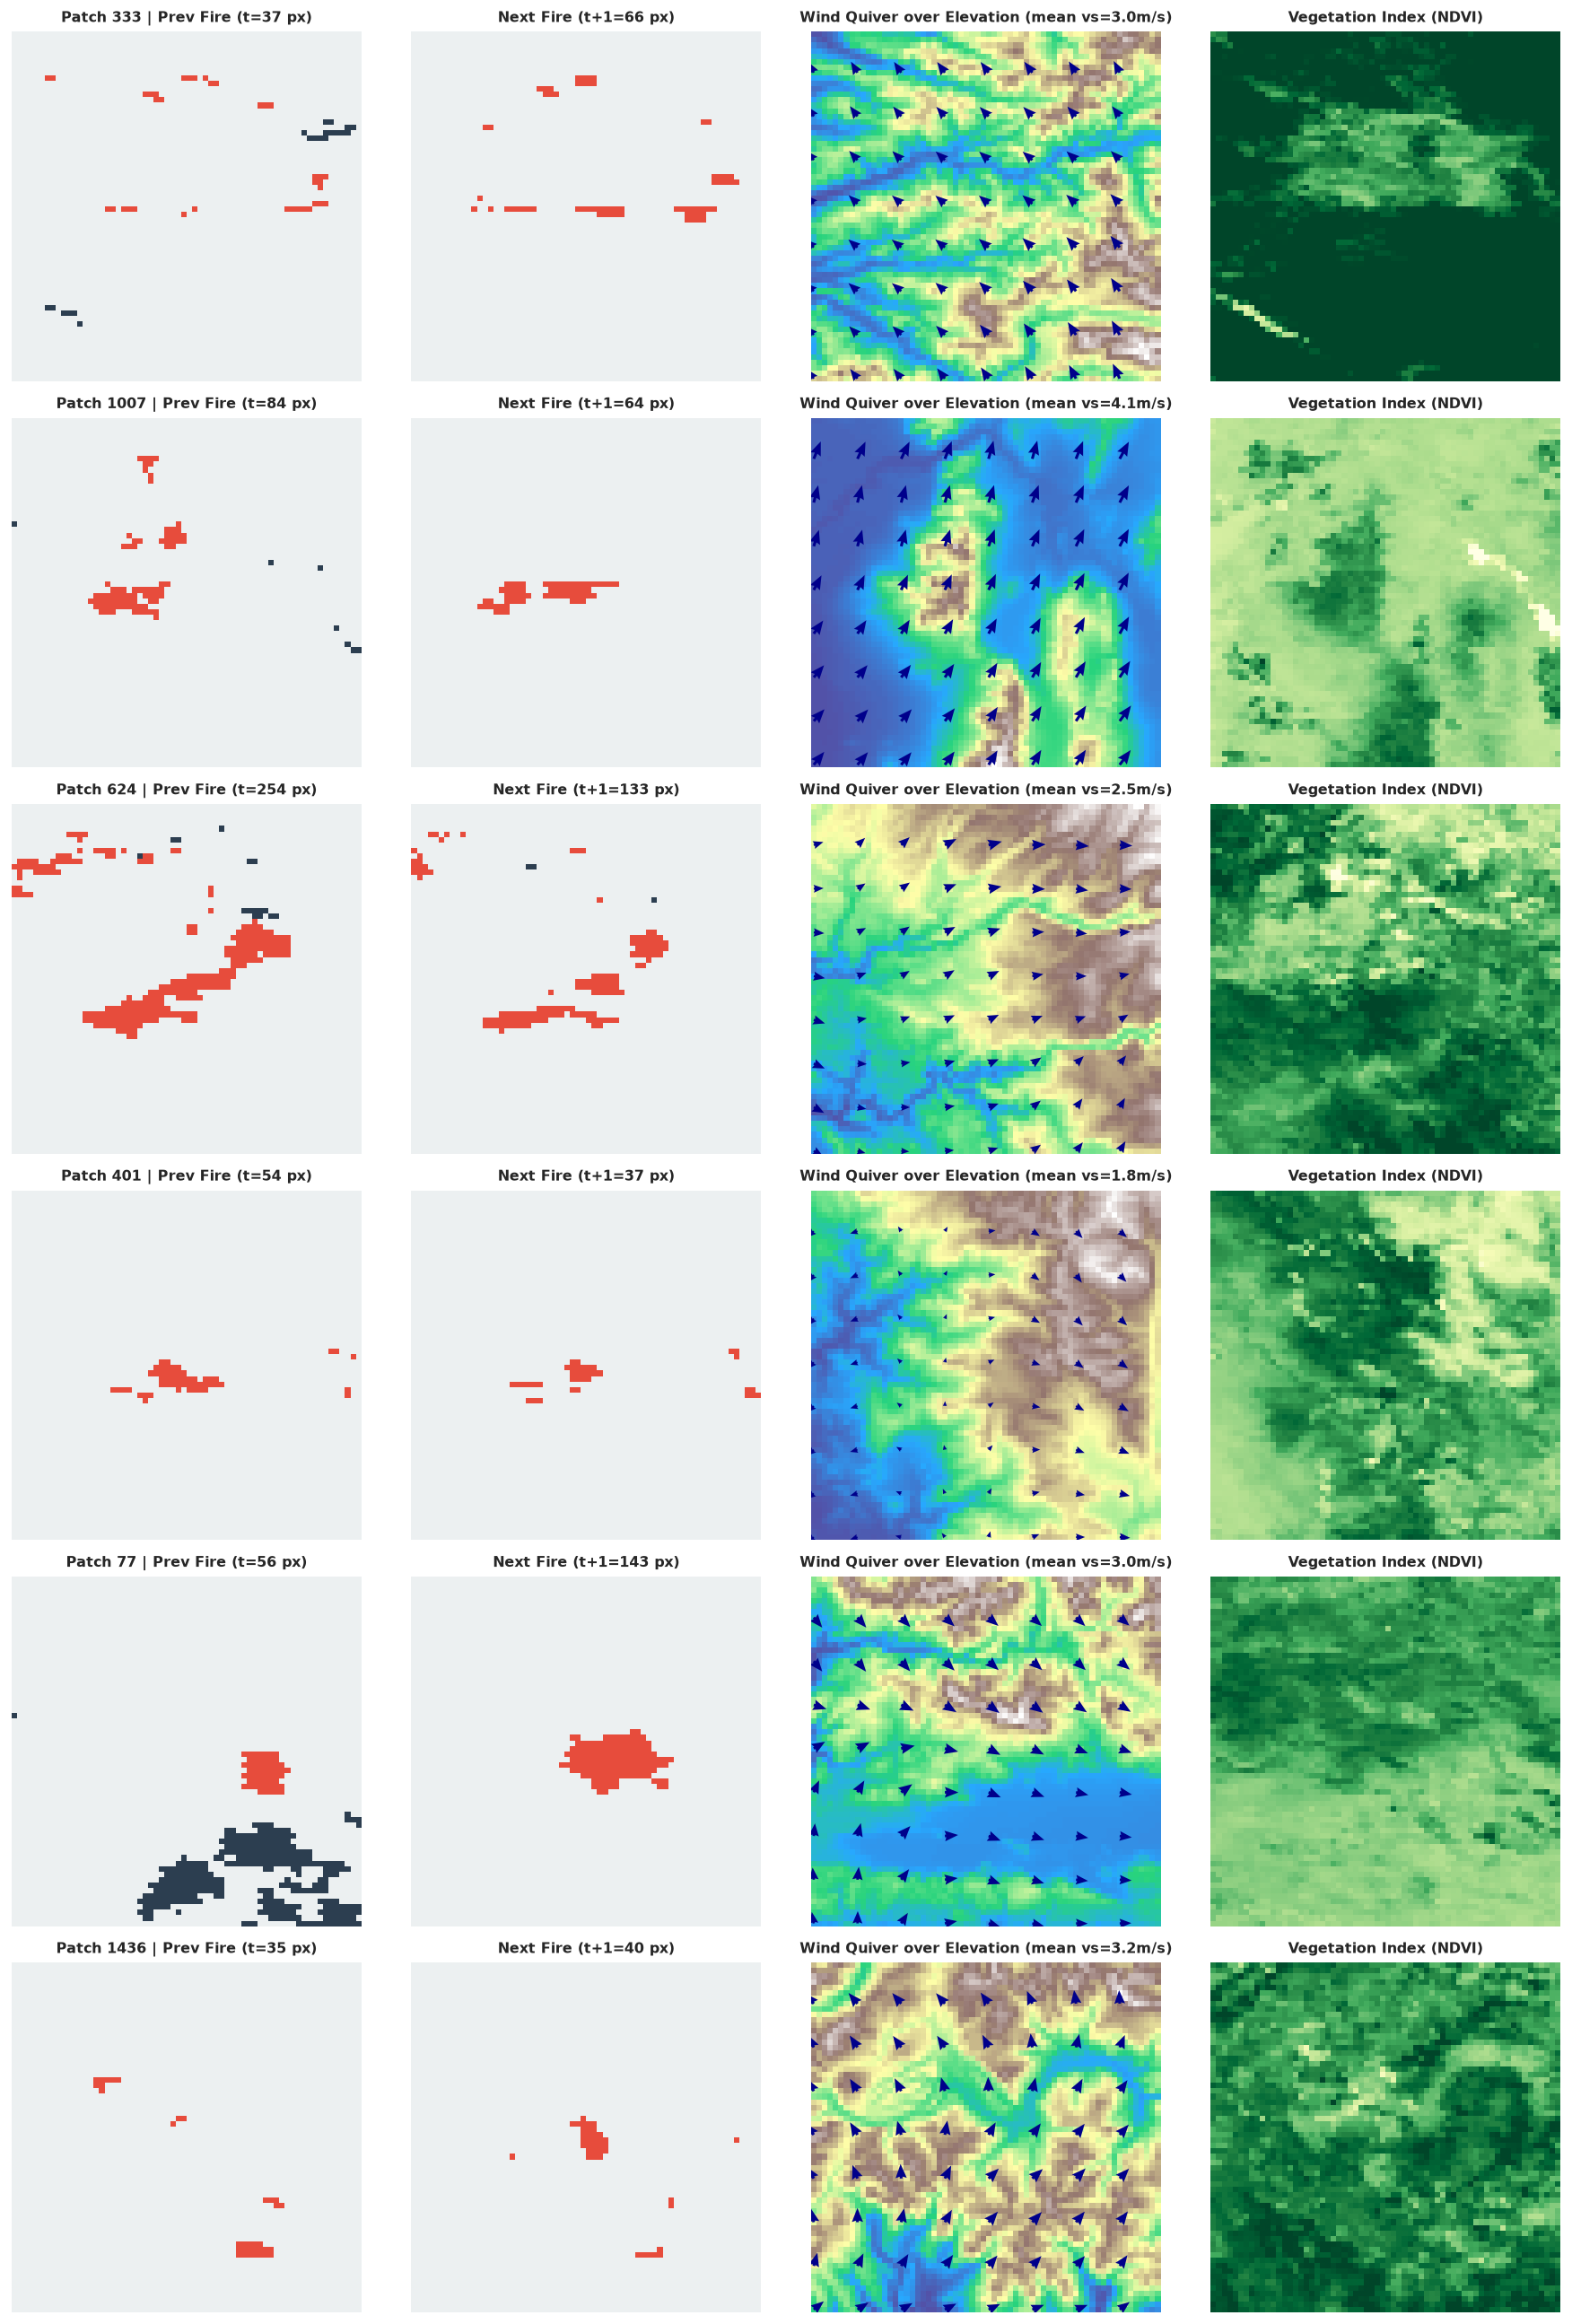

Saved: /Users/harshilvalecha/Semester 5/aml-dl-proj/reports/figures/eda_spatial_examples.png


In [9]:
# Find test patches with meaningful fire (e.g. between 30 and 400 fire pixels on day t)
prev_test_fire = (X_test[:, prev_idx] == 1).sum(axis=(1, 2))
next_test_fire = (y_test == 1).sum(axis=(1, 2))
valid_patch_idx = np.where((prev_test_fire >= 30) & (prev_test_fire <= 400) & (next_test_fire >= 20))[0]

# Pick 6 diverse patches with seed 0
rng_test = np.random.default_rng(SEED)
chosen_patches = rng_test.choice(valid_patch_idx, size=6, replace=False)

fig, axes = plt.subplots(6, 4, figsize=(14, 20))

cmap_mask = plt.matplotlib.colors.ListedColormap(["#2c3e50", "#ecf0f1", "#e74c3c"])
norm_mask = plt.matplotlib.colors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap_mask.N)

elev_idx = CHANNELS.index("elevation")
th_idx = CHANNELS.index("th")
vs_idx = CHANNELS.index("vs")
ndvi_idx = CHANNELS.index("NDVI")

for row_i, p_idx in enumerate(chosen_patches):
    p_prev = X_test[p_idx, prev_idx]
    p_next = y_test[p_idx]
    p_elev = X_test[p_idx, elev_idx]
    p_th = X_test[p_idx, th_idx]
    p_vs = X_test[p_idx, vs_idx]
    p_ndvi = X_test[p_idx, ndvi_idx] / 10_000
    
    # 1. PrevFireMask
    im0 = axes[row_i, 0].imshow(p_prev, cmap=cmap_mask, norm=norm_mask, origin="lower")
    axes[row_i, 0].set_title(f"Patch {p_idx} | Prev Fire (t={(p_prev == 1).sum()} px)", fontsize=9, fontweight="bold")
    axes[row_i, 0].axis("off")
    
    # 2. NextFireMask
    im1 = axes[row_i, 1].imshow(p_next, cmap=cmap_mask, norm=norm_mask, origin="lower")
    axes[row_i, 1].set_title(f"Next Fire (t+1={(p_next == 1).sum()} px)", fontsize=9, fontweight="bold")
    axes[row_i, 1].axis("off")
    
    # 3. Wind Quiver over Elevation
    # Grid for quiver: subsample every 8 pixels
    axes[row_i, 2].imshow(p_elev, cmap="terrain", origin="lower", alpha=0.85)
    step = 8
    Y, X = np.mgrid[0:64:step, 0:64:step]
    
    th_sub = np.deg2rad(p_th[::step, ::step])
    vs_sub = p_vs[::step, ::step]
    
    # GRIDMET: th is direction FROM. Wind blowing from North (th=0) blows towards South (+row, -v)
    # u is eastward (+col), v is northward (-row)
    u = -vs_sub * np.sin(th_sub)
    v = -vs_sub * np.cos(th_sub)
    
    # Patches are stored south-up (row index grows northward, see ROW_TO_NORTH in src/features.py),
    # so every panel uses origin="lower" to draw north at the top; then northward v is +y in data coordinates
    axes[row_i, 2].quiver(X, Y, u, v, color="darkblue", angles="xy", scale=80, width=0.008, headwidth=4)
    axes[row_i, 2].set_title(f"Wind Quiver over Elevation (mean vs={p_vs.mean():.1f}m/s)", fontsize=9, fontweight="bold")
    axes[row_i, 2].axis("off")
    
    # 4. NDVI Vegetation Map
    im3 = axes[row_i, 3].imshow(p_ndvi, cmap="YlGn", origin="lower", vmin=-0.1, vmax=0.8)
    axes[row_i, 3].set_title("Vegetation Index (NDVI)", fontsize=9, fontweight="bold")
    axes[row_i, 3].axis("off")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_spatial_examples.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {FIGURES_DIR / 'eda_spatial_examples.png'}")


> **Takeaway (Spatial Fire Dynamics):**  
> These six test patches (random, seed 0) are illustrative, not evidence on their own. Next-day fire mostly appears on or next to day-$t$ fire, part of the day-$t$ fire disappears, and some new fire appears several km from the previous perimeter. Black pixels are uncertain (`-1`) labels, e.g. patch 77 where much of day $t$ is masked. Whether spread follows the wind is tested quantitatively instead: the upwind fire features rank 4th, 5th and 7th of 35 by gain in the tuned XGBoost.